# 00. Sourcing, wrangling, staging
https://www.kaggle.com/competitions/m5-forecasting-accuracy/data

In [2]:
import glob
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import datetime as dt

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

project_dir = Path.cwd()
data_dir = project_dir / 'Raw Data'

In [25]:
# load main datasets
# use a single store throughout this case study
sales = pd.read_csv(data_dir / 'sales_train_validation.csv', low_memory=False)






sales = sales[sales['store_id'] == 'CA_1'].reset_index().copy() # <-------------- use a single store for this example






calendar = pd.read_csv(data_dir / 'calendar.csv')
sell_prices = pd.read_csv(data_dir / 'sell_prices.csv')

In [30]:
# convert sales from wide to long format
sales_long = sales.melt(
    id_vars=['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id'],
    var_name='d',
    value_name='units_sold'
)

# add calendar dates and features
sales_long = sales_long.merge(
    calendar[
        ['d', 'date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year',
         'event_name_1', 'event_type_1']
    ],
    on='d',
    how='left',
    validate='many_to_one'
)

sales_long = sales_long[sales_long['d']!='index']

In [31]:
sales_long['date'] = pd.to_datetime(sales_long['date'])

# add selling prices
sales_long = sales_long.merge(
    sell_prices[['store_id', 'item_id', 'wm_yr_wk', 'sell_price']],
    on=['store_id', 'item_id', 'wm_yr_wk'],
    how='left',
    validate='many_to_one'
)

sales_long['sell_price'] = sales_long['sell_price'].fillna(0)

In [32]:
# check whether dates are consecutive
dates = sales_long['date'].drop_duplicates().sort_values()

expected_dates = pd.date_range(
    start=dates.min(),
    end=dates.max(),
    freq='D'
)

missing_dates = expected_dates.difference(dates)

if len(missing_dates) > 0:
    raise ValueError(f'missing dates: {missing_dates.tolist()}')

print('all dates are consecutive')

all dates are consecutive


# Exploratory Data Analysis (EDA)

In [34]:
sales_long.dtypes

id                      object
item_id                 object
dept_id                 object
cat_id                  object
store_id                object
state_id                object
d                       object
units_sold               int64
date            datetime64[ns]
wm_yr_wk               float64
weekday                 object
wday                   float64
month                  float64
year                   float64
event_name_1            object
event_type_1            object
sell_price             float64
dtype: object

In [35]:
len(sales_long)

5832737

## cat_id
Items from FOODS sell the most and for the cheapest.

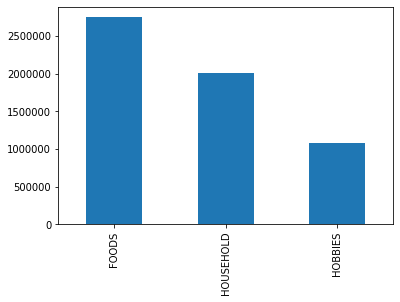

In [37]:
sales_long['cat_id'].value_counts().plot(kind='bar')

In [38]:
sales_long.groupby('cat_id')[['sell_price']].describe()

sell_price                                                  
               count      mean       std  min   25%   50%   75%    max
cat_id                                                                
FOODS      2748981.0  2.652471  2.315165  0.0  1.00  2.48  3.50  19.48
HOBBIES    1080845.0  4.293541  4.831454  0.0  0.58  2.88  5.98  30.98
HOUSEHOLD  2002911.0  4.400358  3.719512  0.0  1.77  3.97  5.97  29.97

## sell_price
It's interesting that FOODS is a distinct group, while HOBBIES has the widest range.  

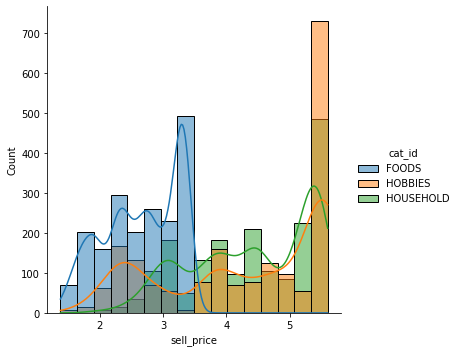

In [39]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning, module='matplotlib')

# plot avgs; raw dataset too large for sns
grp = sales_long.groupby(['d','cat_id'], as_index=False)[['sell_price']].mean()
sns.displot(data=grp, x="sell_price", hue="cat_id", kde=True)

plt.show()

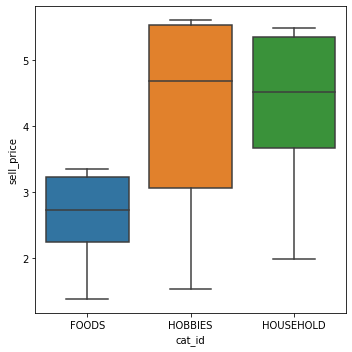

In [40]:
# plot box plots
plt.figure(figsize=(5, 5))
sns.boxplot(data=grp, x='cat_id', y='sell_price')

plt.tight_layout()
plt.show()

90%      7.94
91%      7.98
92%      8.66
93%      8.97
94%      9.84
95%      9.98
96%     10.98
97%     11.97
98%     12.97
99%     15.94
100%    30.98
Name: sell_price, dtype: float64


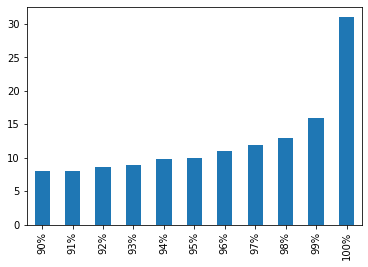

In [41]:
# view the percentiles of sell_price

df = sales_long['sell_price'].describe(percentiles = np.arange(0,1.01,0.01))
df2 = df.loc['90%':'100%']
print(df2)
df2.plot(kind='bar')

## date

In [42]:
d1 = sales_long['date'].min()
d2 = sales_long['date'].max()

print(d1.date(), d2.date())
print(f"~{np.round((d2-d1).days/365)} years")

2011-01-29 2016-04-24
~5.0 years


## event_type_1 and event_name_1
Overall, the least number of units are sold on national holidays.    
We see that Labor Day sells the most units while Christmas sells the least.

In [43]:
sales_long['event_type_1'].value_counts()

Religious    158548
National     155499
Cultural     106715
Sporting      48784
Name: event_type_1, dtype: int64

In [44]:
sales_long['event_name_1'].value_counts()

SuperBowl              18294
PresidentsDay          18294
LentStart              18294
LentWeek2              18294
StPatricksDay          18294
Purim End              18294
ValentinesDay          18294
Thanksgiving           15245
Halloween              15245
EidAlAdha              15245
VeteransDay            15245
NewYear                15245
Christmas              15245
Chanukah End           15245
LaborDay               15245
OrthodoxChristmas      15245
MartinLutherKingDay    15245
ColumbusDay            15245
IndependenceDay        15245
Eid al-Fitr            15245
Ramadan starts         15245
NBAFinalsEnd           15245
NBAFinalsStart         15245
MemorialDay            15245
Mother's day           15245
Pesach End             15245
Easter                 15245
Father's day           12196
Cinco De Mayo          12196
OrthodoxEaster         12196
Name: event_name_1, dtype: int64

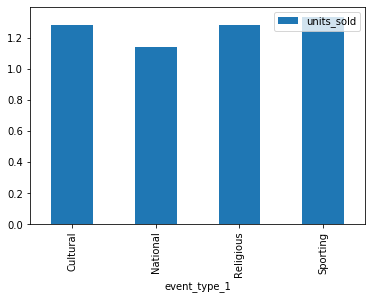

In [45]:
sales_long.groupby('event_type_1')[['units_sold']].mean().plot(kind='bar')

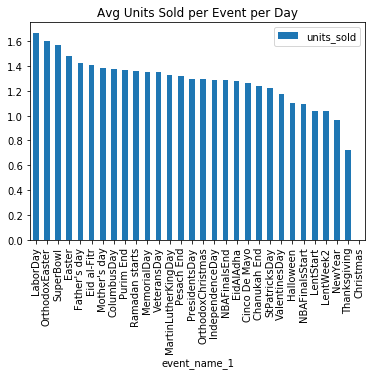

In [46]:
(
    sales_long
    .groupby('event_name_1')[['units_sold']]
    .mean()
    .sort_values('units_sold', ascending = False)
    .plot(kind='bar', title = 'Avg Units Sold per Event per Day')
)

In [47]:
# confirm the low value
sales_long[sales_long['event_name_1']=='Christmas'][['units_sold']].sum()

units_sold    0
dtype: int64

In [48]:
# confirm date range
print(np.min(sorted(sales_long['date'].unique())))
print(np.max(sorted(sales_long['date'].unique())))

2011-01-29T00:00:00.000000000
2016-04-24T00:00:00.000000000


# Write data for downstream modeling

In [58]:
# recall the level of this dataset
# i.e. a single store with many items over many dates
sales_long.groupby(['store_id','date','cat_id'])[['item_id']].nunique()

item_id
store_id date       cat_id            
CA_1     2011-01-29 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-01-30 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-01-31 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-01 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-02 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-03 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-04 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-05 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-06 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-07 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-08 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-09 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-10 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-11 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-12 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-13 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-14 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-15 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-16 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-17 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-18 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-19 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-20 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-21 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-22 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-23 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-24 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-25 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-26 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-27 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-02-28 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-03-01 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-03-02 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-03-03 FOODS         1437
                    HOBBIES        565
              

In [50]:
print('rows:', len(sales_long))
print('memory in GB:', round(
    sales_long.memory_usage(deep=True).sum() / 1024**3, 2
))
sales_long.to_csv(data_dir / 'sales_long.csv', index=False)

rows: 5832737
memory in GB: 3.73


In [ ]:
print('done')